# Cart Abandonment Pattern Analysis
## Notebook 3: Exploratory Data Analysis (EDA) & Visualizations

**Purpose:** Answer the 7 business questions visually using the clean dataset.

| # | Analysis |
|---|---|
| 1 | Funnel drop-off by checkout step |
| 2 | Device type — conversion & abandonment |
| 3 | Product category — highest abandonment |
| 4 | Time of day — peak abandonment hours |
| 5 | Day of week — highest drop-off day |
| 6 | Customer type — New vs Returning |
| 7 | Estimated revenue lost from abandoned carts |

> All charts use the **clean dataset** (`kz_clean.csv`). Every number comes from the data.


## 0. Imports & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── Plot style ──────────────────────────────────────────
plt.rcParams.update({
    'figure.figsize'  : (13, 6),
    'axes.spines.top' : False,
    'axes.spines.right': False,
    'axes.titlesize'  : 14,
    'axes.titleweight': 'bold',
    'axes.labelsize'  : 11,
    'xtick.labelsize' : 10,
    'ytick.labelsize' : 10,
    'figure.dpi'      : 110,
})
COLORS = ['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860']
sns.set_palette(COLORS)

print("Setup complete")

Setup complete


## 1. Load Clean Dataset

In [2]:
CLEAN_PATH = r'..\data\kz_clean.csv'

print('Loading cleaned data...')
df = pd.read_csv(CLEAN_PATH, parse_dates=['event_time'])
print(f'Rows    : {len(df):,}')
print(f'Columns : {list(df.columns)}')
df.head(3)

Loading cleaned data...
Rows    : 1,504,592
Columns : ['event_time', 'order_id', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'hour', 'day_of_week', 'time_bucket', 'cart_value', 'interaction_count', 'checkout_step', 'device_type_simulated', 'first_order_id', 'customer_type', 'abandoned_flag']


,event_time,order_id,product_id,category_id,category_code,brand,price,user_id,hour,day_of_week,time_bucket,cart_value,interaction_count,checkout_step,device_type_simulated,first_order_id,customer_type,abandoned_flag
0,2020-04-24 11:50:39+00:00,2294359932054536986,1515966223509089906,2268105426648171008,electronics.tablet,samsung,162.01,1515915625441993984,11,Friday,Morning,162.01,1,Cart,Mobile,2.294360e+18,Returning,1
1,2020-04-24 14:37:43+00:00,2294444024058086220,2273948319057183658,2268105430162997760,electronics.audio.headphone,huawei,77.52,1515915625447879424,14,Friday,Afternoon,77.52,1,Cart,Tablet,2.294444e+18,Returning,1
2,2020-04-24 19:16:21+00:00,2294584263154074236,2273948316817424439,2268105471367840000,Unknown,karcher,217.57,1515915625443148032,19,Friday,Evening,217.57,1,Cart,Desktop,2.294584e+18,Returning,1


## Analysis 1 — Checkout Funnel Drop-off

**Business Question:** At which step do we lose the most customers?

The funnel has 5 stages (in order):
Cart → Login/Address → Shipping → Payment → Order Confirmation


=== FUNNEL ANALYSIS ===
              Step  Orders  Drop_Off  Drop_Off_%  Conv_%
              Cart  447041       NaN         NaN   100.0
     Login/Address  164727  282314.0        63.2    36.8
          Shipping   78611   86116.0        52.3    17.6
           Payment   37692   40919.0        52.1     8.4
Order Confirmation   51050  -13358.0       -35.4    11.4


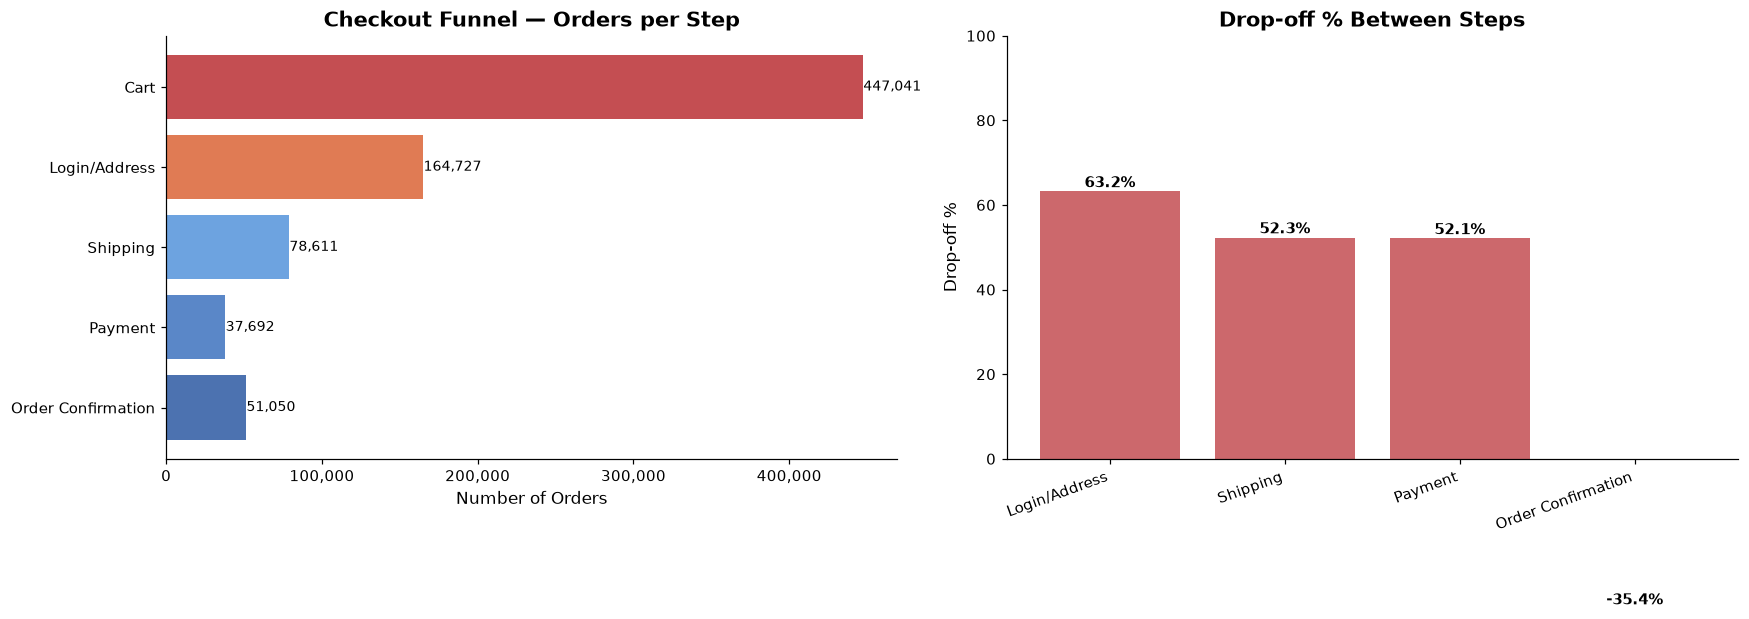


>>> BIGGEST DROP-OFF: 'Login/Address' with 63.2% drop


In [3]:
# Define funnel order
FUNNEL_ORDER = ['Cart', 'Login/Address', 'Shipping', 'Payment', 'Order Confirmation']

# Count unique orders at each step
funnel = (
    df.groupby('checkout_step')['order_id']
    .nunique()
    .reindex(FUNNEL_ORDER)
    .reset_index()
)
funnel.columns = ['Step', 'Orders']

# Calculate drop-off and % at each step
funnel['Drop_Off']   = funnel['Orders'].shift(1) - funnel['Orders']
funnel['Drop_Off_%'] = (funnel['Drop_Off'] / funnel['Orders'].shift(1) * 100).round(1)
funnel['Conv_%']     = (funnel['Orders'] / funnel['Orders'].iloc[0] * 100).round(1)

print("=== FUNNEL ANALYSIS ===")
print(funnel.to_string(index=False))

# ── Chart ────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left: Funnel bar
bars = ax1.barh(funnel['Step'][::-1], funnel['Orders'][::-1],
                color=['#4C72B0','#5A87C8','#6DA3E0','#E07B54','#C44E52'])
ax1.set_xlabel('Number of Orders')
ax1.set_title('Checkout Funnel — Orders per Step')
for bar, val in zip(bars, funnel['Orders'][::-1]):
    ax1.text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2,
             f'{val:,}', va='center', fontsize=9)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

# Right: Drop-off % bar (skip first row — no previous step)
dropoff_data = funnel.dropna(subset=['Drop_Off_%'])
bars2 = ax2.bar(dropoff_data['Step'], dropoff_data['Drop_Off_%'],
                color='#C44E52', alpha=0.85)
ax2.set_ylabel('Drop-off %')
ax2.set_title('Drop-off % Between Steps')
ax2.set_ylim(0, 100)
for bar, val in zip(bars2, dropoff_data['Drop_Off_%']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{val}%', ha='center', fontsize=10, fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(r'..\reports\funnel_analysis.png', bbox_inches='tight')
plt.show()

biggest_drop = funnel.loc[funnel['Drop_Off_%'].idxmax()]
print(f"\n>>> BIGGEST DROP-OFF: '{biggest_drop['Step']}' with {biggest_drop['Drop_Off_%']:.1f}% drop")

## Analysis 2 — Device Type: Conversion & Abandonment

**Business Question:** Which device has the highest abandonment rate?

> Note: `device_type_simulated` is a simulated column (Mobile 55%, Desktop 35%, Tablet 10%).


=== DEVICE TYPE ANALYSIS ===
device_type_simulated  Total_Orders  Abandoned  Completed  Abandonment_Rate%  Conversion_Rate%
              Desktop        387083     407140     -20057              105.2              -5.2
               Mobile        535240     639768    -104528              119.5             -19.5
               Tablet        135483     116188      19295               85.8              14.2


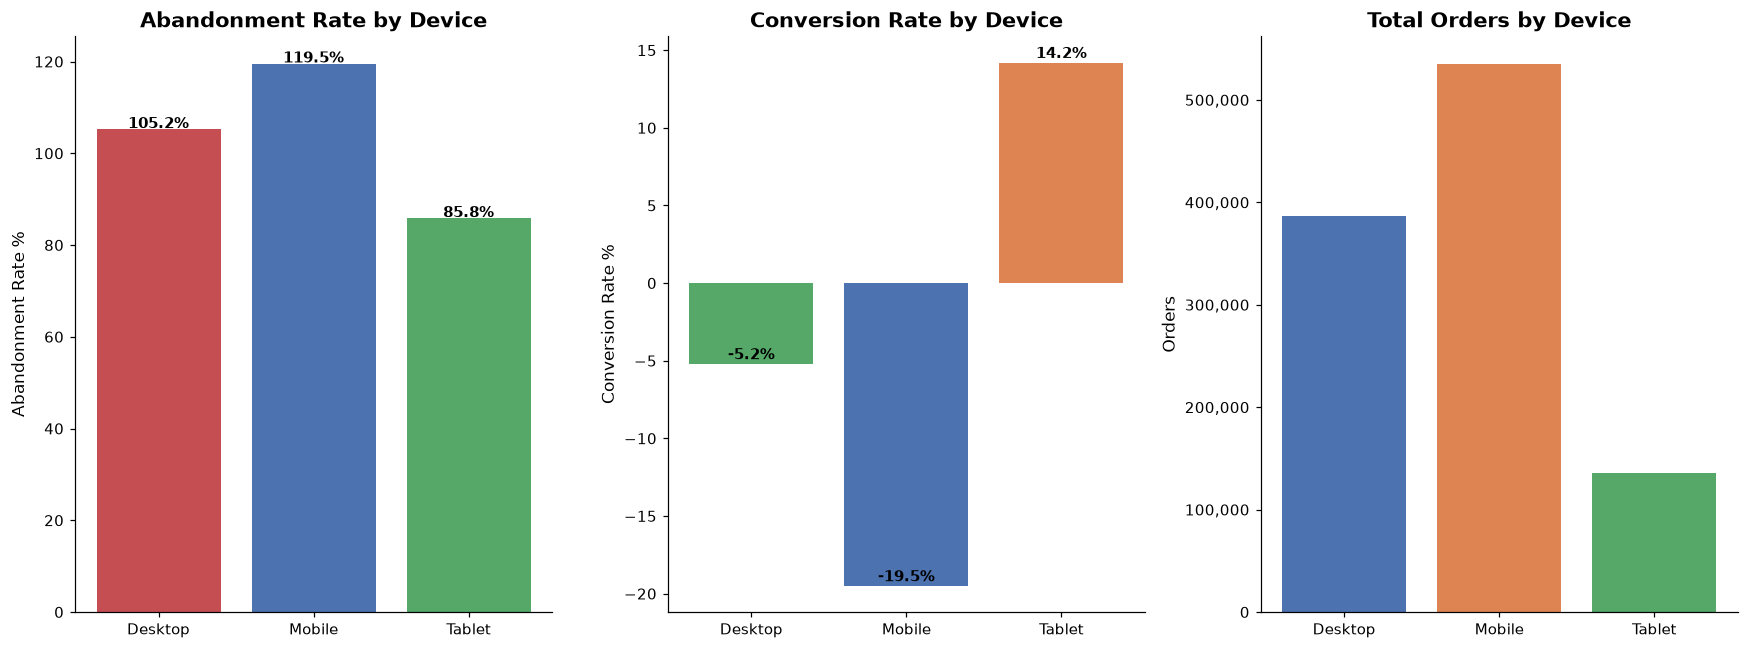

In [4]:
device_stats = df.groupby('device_type_simulated').agg(
    Total_Orders   = ('order_id', 'nunique'),
    Abandoned      = ('abandoned_flag', 'sum'),
).reset_index()

device_stats['Completed']        = device_stats['Total_Orders'] - device_stats['Abandoned']
device_stats['Abandonment_Rate%'] = (device_stats['Abandoned'] / device_stats['Total_Orders'] * 100).round(1)
device_stats['Conversion_Rate%']  = (device_stats['Completed'] / device_stats['Total_Orders'] * 100).round(1)

print("=== DEVICE TYPE ANALYSIS ===")
print(device_stats.to_string(index=False))

# ── Chart ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
devices = device_stats['device_type_simulated']

axes[0].bar(devices, device_stats['Abandonment_Rate%'], color=['#C44E52','#4C72B0','#55A868'])
axes[0].set_title('Abandonment Rate by Device')
axes[0].set_ylabel('Abandonment Rate %')
for i, v in enumerate(device_stats['Abandonment_Rate%']):
    axes[0].text(i, v+0.3, f'{v}%', ha='center', fontweight='bold')

axes[1].bar(devices, device_stats['Conversion_Rate%'], color=['#55A868','#4C72B0','#DD8452'])
axes[1].set_title('Conversion Rate by Device')
axes[1].set_ylabel('Conversion Rate %')
for i, v in enumerate(device_stats['Conversion_Rate%']):
    axes[1].text(i, v+0.3, f'{v}%', ha='center', fontweight='bold')

axes[2].bar(devices, device_stats['Total_Orders'], color=COLORS[:3])
axes[2].set_title('Total Orders by Device')
axes[2].set_ylabel('Orders')
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig(r'..\reports\device_analysis.png', bbox_inches='tight')
plt.show()

## Analysis 3 — Product Category Abandonment

**Business Question:** Which product categories have the highest abandonment?


=== TOP 10 CATEGORIES BY ABANDONMENT RATE ===
                 category_code  Total  Abandoned  Abandon_%
           stationery.cartrige   3624       5291      146.0
appliances.environment.climate    106        121      114.2
                         23.13    237        260      109.7
      computers.components.cpu   6262       6695      106.9
            stationery.battery  13349      14234      106.6
                apparel.tshirt    909        965      106.2
   electronics.video.projector    122        126      103.3
      electronics.camera.photo    200        205      102.5
       furniture.kitchen.table  29183      29043       99.5
    appliances.environment.fan   5083       5026       98.9


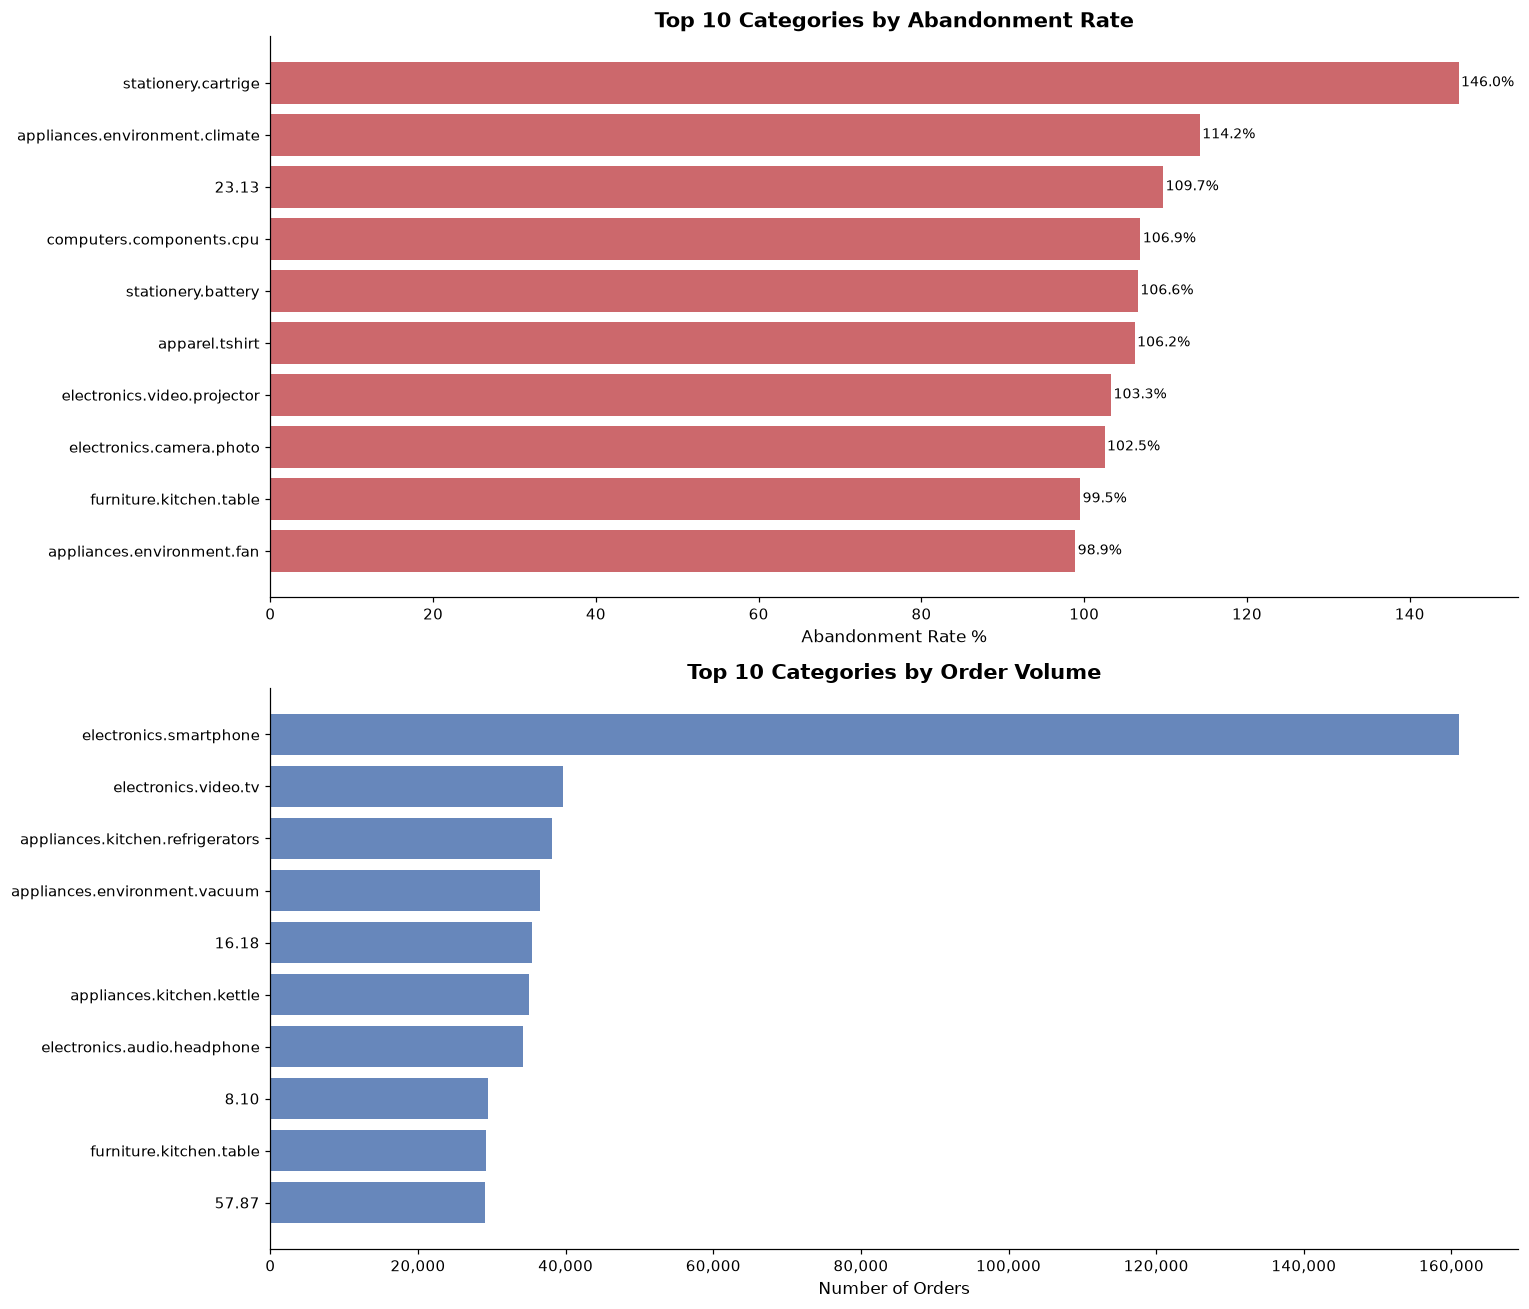

In [5]:
cat_stats = (
    df[df['category_code'] != 'Unknown']
    .groupby('category_code')
    .agg(
        Total      = ('order_id', 'nunique'),
        Abandoned  = ('abandoned_flag', 'sum'),
        Avg_Cart   = ('cart_value', 'mean')
    )
    .reset_index()
)
cat_stats['Abandon_%'] = (cat_stats['Abandoned'] / cat_stats['Total'] * 100).round(1)
cat_stats = cat_stats[cat_stats['Total'] >= 100]  # filter low-volume categories

top10_abandon = cat_stats.nlargest(10, 'Abandon_%')
top10_volume  = cat_stats.nlargest(10, 'Total')

print("=== TOP 10 CATEGORIES BY ABANDONMENT RATE ===")
print(top10_abandon[['category_code','Total','Abandoned','Abandon_%']].to_string(index=False))

# ── Chart ────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12))

# Top 10 by abandonment %
ax1.barh(top10_abandon['category_code'][::-1], top10_abandon['Abandon_%'][::-1],
         color='#C44E52', alpha=0.85)
ax1.set_xlabel('Abandonment Rate %')
ax1.set_title('Top 10 Categories by Abandonment Rate')
for i, (cat, val) in enumerate(zip(top10_abandon['category_code'][::-1],
                                    top10_abandon['Abandon_%'][::-1])):
    ax1.text(val + 0.3, i, f'{val}%', va='center', fontsize=9)

# Top 10 by volume
ax2.barh(top10_volume['category_code'][::-1], top10_volume['Total'][::-1],
         color='#4C72B0', alpha=0.85)
ax2.set_xlabel('Number of Orders')
ax2.set_title('Top 10 Categories by Order Volume')
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig(r'..\reports\category_analysis.png', bbox_inches='tight')
plt.show()

## Analysis 4 — Time of Day: Peak Abandonment

**Business Question:** When during the day do most abandonments happen?


=== TIME BUCKET ANALYSIS ===
time_bucket  Total  Abandoned  Abandon_%
    Morning 565414     848674      150.1
  Afternoon 168748     253012      149.9
    Evening   5042       6245      123.9
      Night  39917      55165      138.2

Peak abandonment hour: 10:00  (138,911 abandonments)


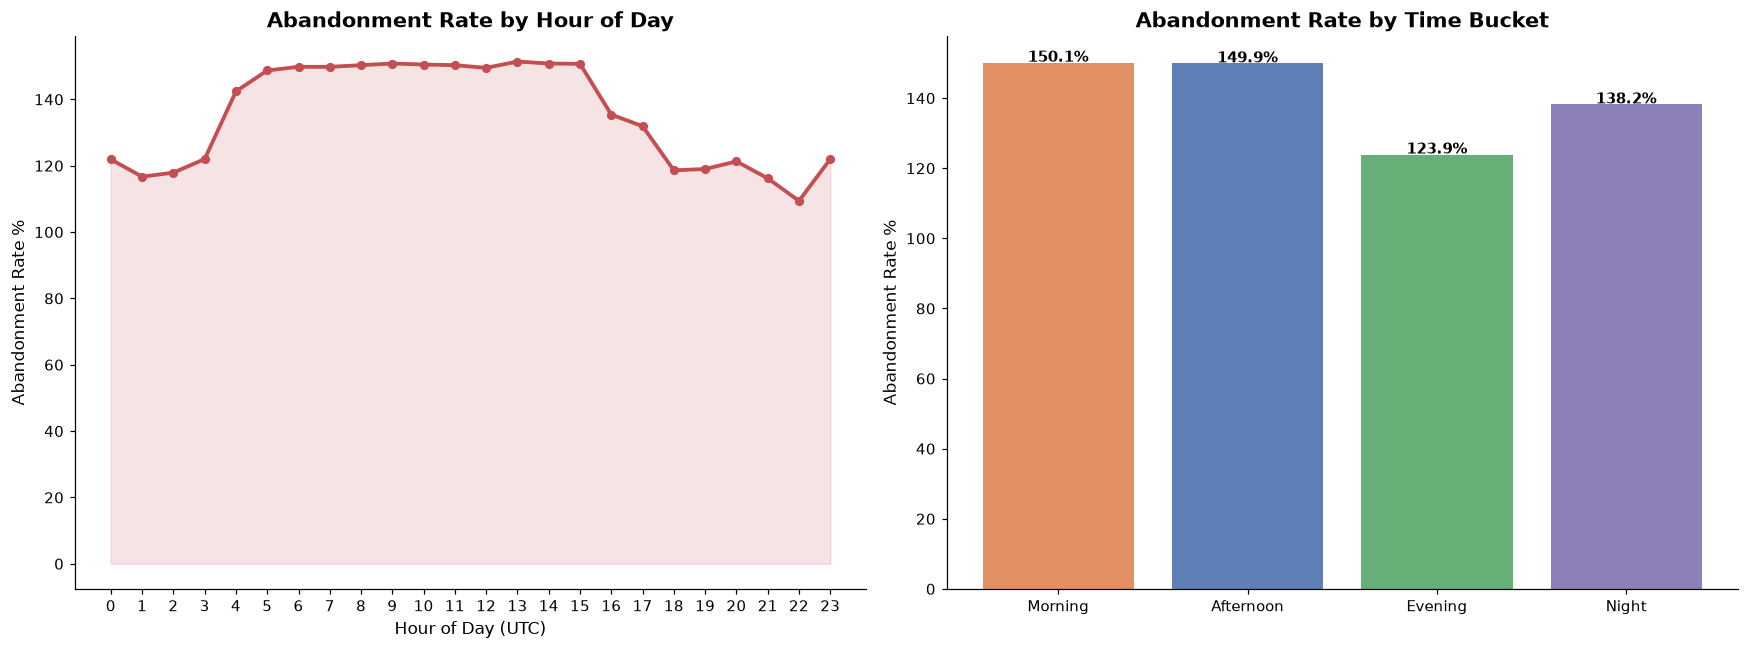

In [6]:
# Hourly abandonment
hourly = df.groupby('hour').agg(
    Total     = ('order_id', 'nunique'),
    Abandoned = ('abandoned_flag', 'sum')
).reset_index()
hourly['Abandon_%'] = (hourly['Abandoned'] / hourly['Total'] * 100).round(1)

# Time bucket abandonment
bucket_stats = df.groupby('time_bucket').agg(
    Total     = ('order_id', 'nunique'),
    Abandoned = ('abandoned_flag', 'sum')
).reset_index()
bucket_stats['Abandon_%'] = (bucket_stats['Abandoned'] / bucket_stats['Total'] * 100).round(1)
BUCKET_ORDER = ['Morning','Afternoon','Evening','Night']
bucket_stats = bucket_stats.set_index('time_bucket').reindex(BUCKET_ORDER).reset_index()

print("=== TIME BUCKET ANALYSIS ===")
print(bucket_stats.to_string(index=False))
print()
peak_hour = hourly.loc[hourly['Abandoned'].idxmax()]
print(f"Peak abandonment hour: {int(peak_hour['hour'])}:00  ({int(peak_hour['Abandoned']):,} abandonments)")

# ── Chart ────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(hourly['hour'], hourly['Abandon_%'], color='#C44E52', linewidth=2.5, marker='o', markersize=5)
ax1.fill_between(hourly['hour'], hourly['Abandon_%'], alpha=0.15, color='#C44E52')
ax1.set_xlabel('Hour of Day (UTC)')
ax1.set_ylabel('Abandonment Rate %')
ax1.set_title('Abandonment Rate by Hour of Day')
ax1.set_xticks(range(0, 24))

palette = ['#DD8452','#4C72B0','#55A868','#8172B2']
ax2.bar(bucket_stats['time_bucket'], bucket_stats['Abandon_%'], color=palette, alpha=0.9)
ax2.set_ylabel('Abandonment Rate %')
ax2.set_title('Abandonment Rate by Time Bucket')
for i, v in enumerate(bucket_stats['Abandon_%']):
    ax2.text(i, v + 0.3, f'{v}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(r'..\reports\time_analysis.png', bbox_inches='tight')
plt.show()

## Analysis 5 — Day of Week: Highest Drop-off Day

**Business Question:** Which day of the week has the most abandonments?


=== DAY OF WEEK ANALYSIS ===
day_of_week  Total  Abandoned  Abandon_%
     Monday  99726     144859      145.3
    Tuesday 101531     148072      145.8
  Wednesday  91383     132969      145.5
   Thursday  92648     136869      147.7
     Friday 110090     165765      150.6
   Saturday 140869     215583      153.0
     Sunday 142874     218979      153.3

>>> Highest drop-off day: Sunday (153.3%)


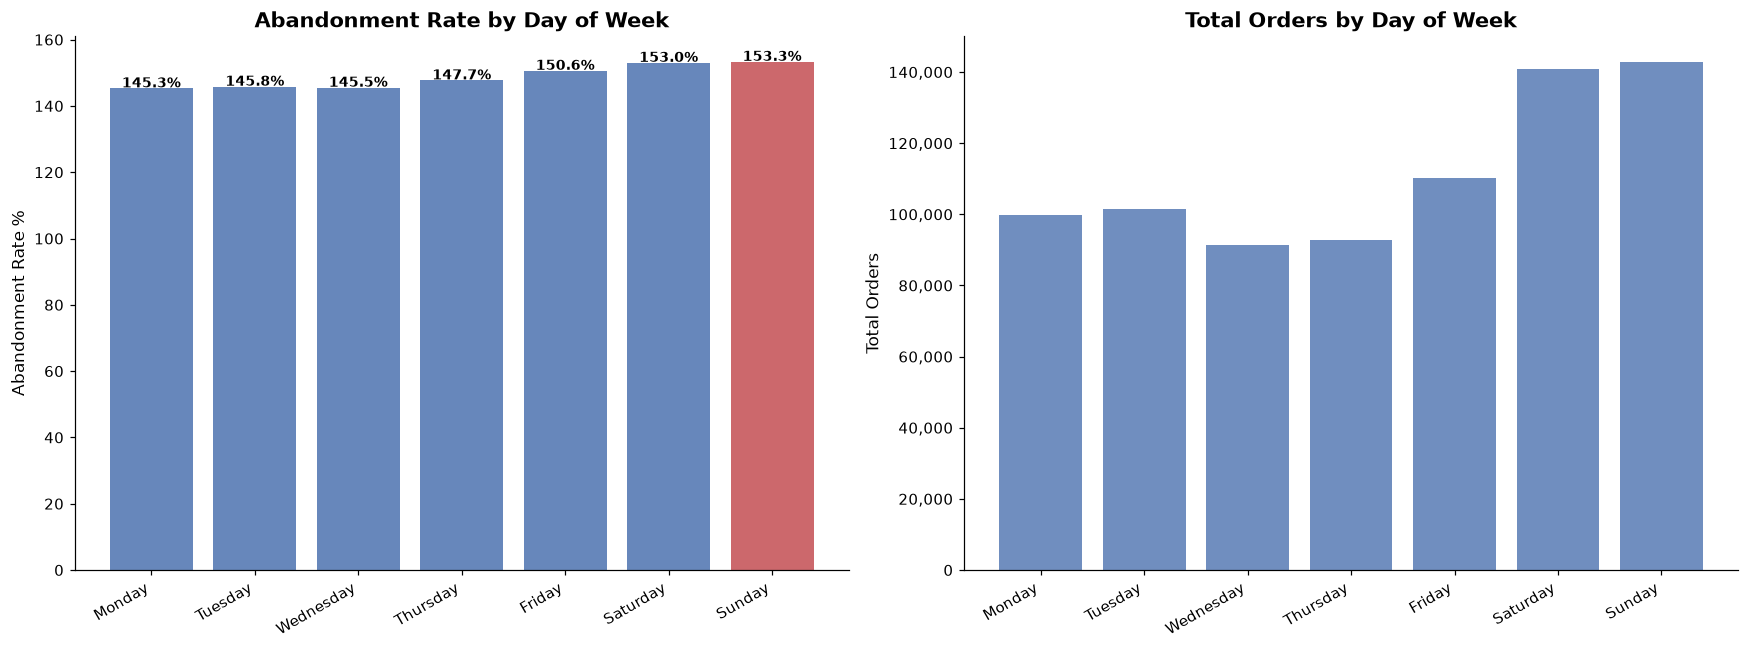

In [7]:
DAY_ORDER = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

day_stats = df.groupby('day_of_week').agg(
    Total     = ('order_id', 'nunique'),
    Abandoned = ('abandoned_flag', 'sum')
).reset_index()
day_stats['Abandon_%'] = (day_stats['Abandoned'] / day_stats['Total'] * 100).round(1)
day_stats = day_stats.set_index('day_of_week').reindex(DAY_ORDER).reset_index()

print("=== DAY OF WEEK ANALYSIS ===")
print(day_stats.to_string(index=False))
worst_day = day_stats.loc[day_stats['Abandon_%'].idxmax()]
print(f"\n>>> Highest drop-off day: {worst_day['day_of_week']} ({worst_day['Abandon_%']}%)")

# ── Chart ────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

colors_days = ['#C44E52' if d == worst_day['day_of_week'] else '#4C72B0'
               for d in day_stats['day_of_week']]

ax1.bar(day_stats['day_of_week'], day_stats['Abandon_%'], color=colors_days, alpha=0.85)
ax1.set_ylabel('Abandonment Rate %')
ax1.set_title('Abandonment Rate by Day of Week')
for i, v in enumerate(day_stats['Abandon_%']):
    ax1.text(i, v + 0.3, f'{v}%', ha='center', fontsize=9, fontweight='bold')
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right')

ax2.bar(day_stats['day_of_week'], day_stats['Total'], color='#4C72B0', alpha=0.8)
ax2.set_ylabel('Total Orders')
ax2.set_title('Total Orders by Day of Week')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.savefig(r'..\reports\dayofweek_analysis.png', bbox_inches='tight')
plt.show()

## Analysis 6 — Customer Type: New vs Returning

**Business Question:** Do new customers abandon more than returning ones?


=== CUSTOMER TYPE ANALYSIS ===
customer_type  Total  Abandoned  Avg_Cart  Abandon_%  Conversion_%
    Anonymous 692091    1043747    375.14      150.8         -50.8
          New     83         97    324.45      116.9         -16.9
    Returning  92645     119252    274.59      128.7         -28.7


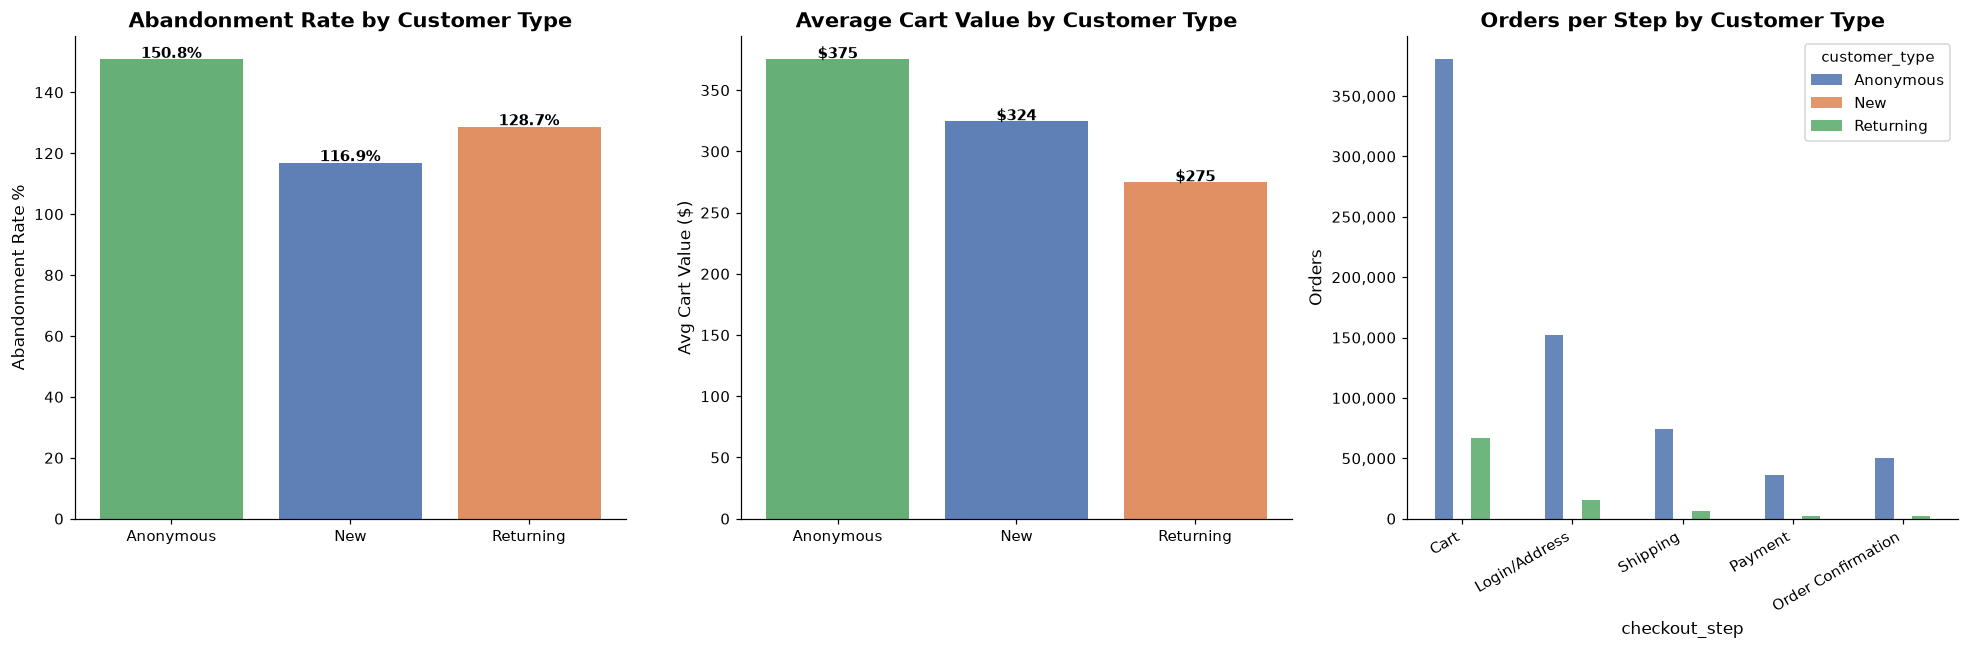

In [8]:
ctype_stats = df.groupby('customer_type').agg(
    Total     = ('order_id', 'nunique'),
    Abandoned = ('abandoned_flag', 'sum'),
    Avg_Cart  = ('cart_value', 'mean')
).reset_index()
ctype_stats['Abandon_%']    = (ctype_stats['Abandoned'] / ctype_stats['Total'] * 100).round(1)
ctype_stats['Conversion_%'] = (100 - ctype_stats['Abandon_%']).round(1)
ctype_stats['Avg_Cart']     = ctype_stats['Avg_Cart'].round(2)

print("=== CUSTOMER TYPE ANALYSIS ===")
print(ctype_stats.to_string(index=False))

# Step where each customer type drops off
step_ctype = df.groupby(['customer_type','checkout_step'])['order_id'].nunique().reset_index()
step_ctype.columns = ['customer_type','checkout_step','orders']

# ── Chart ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

colors_ct = ['#55A868','#4C72B0','#DD8452']

axes[0].bar(ctype_stats['customer_type'], ctype_stats['Abandon_%'], color=colors_ct, alpha=0.9)
axes[0].set_title('Abandonment Rate by Customer Type')
axes[0].set_ylabel('Abandonment Rate %')
for i, v in enumerate(ctype_stats['Abandon_%']):
    axes[0].text(i, v + 0.5, f'{v}%', ha='center', fontweight='bold')

axes[1].bar(ctype_stats['customer_type'], ctype_stats['Avg_Cart'], color=colors_ct, alpha=0.9)
axes[1].set_title('Average Cart Value by Customer Type')
axes[1].set_ylabel('Avg Cart Value ($)')
for i, v in enumerate(ctype_stats['Avg_Cart']):
    axes[1].text(i, v + 1, f'${v:.0f}', ha='center', fontweight='bold')

pivot = step_ctype.pivot(index='checkout_step', columns='customer_type', values='orders').reindex(
    ['Cart','Login/Address','Shipping','Payment','Order Confirmation'])
pivot.plot(kind='bar', ax=axes[2], alpha=0.85)
axes[2].set_title('Orders per Step by Customer Type')
axes[2].set_ylabel('Orders')
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
plt.setp(axes[2].xaxis.get_majorticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.savefig(r'..\reports\customer_type_analysis.png', bbox_inches='tight')
plt.show()

## Analysis 7 — Revenue Lost from Abandoned Carts

**Business Question:** How much revenue are we leaving on the table?


=== REVENUE ANALYSIS ===
Revenue Captured  : $  36,193,760.16
Revenue LOST      : $ 139,914,670.05  (79.4% of total potential)
Total Potential   : $ 176,108,430.21

=== REVENUE LOST BY STEP ===
         Step  Revenue_Lost
         Cart   53861087.88
Login/Address   77002604.40
     Shipping   87521333.76
      Payment   73514008.20


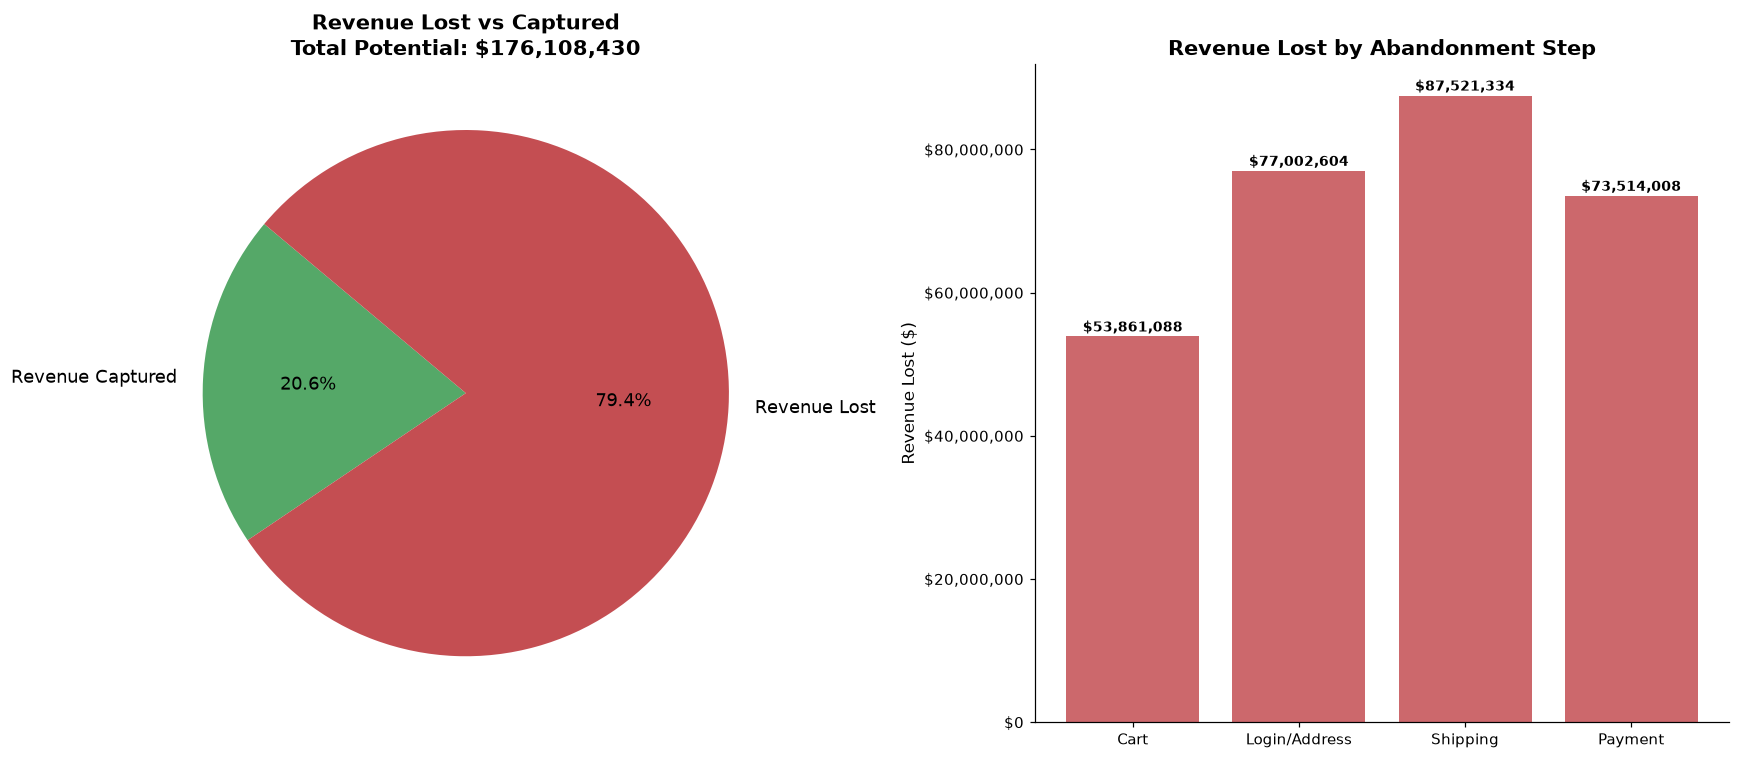

In [9]:
# Total revenue lost = sum of cart_value for abandoned orders
abandoned_orders = df[df['abandoned_flag'] == 1].groupby('order_id')['cart_value'].first()
completed_orders = df[df['abandoned_flag'] == 0].groupby('order_id')['cart_value'].first()

rev_lost      = abandoned_orders.sum()
rev_captured  = completed_orders.sum()
total_rev     = rev_lost + rev_captured
loss_pct      = rev_lost / total_rev * 100

print("=== REVENUE ANALYSIS ===")
print(f"Revenue Captured  : ${rev_captured:>15,.2f}")
print(f"Revenue LOST      : ${rev_lost:>15,.2f}  ({loss_pct:.1f}% of total potential)")
print(f"Total Potential   : ${total_rev:>15,.2f}")

# Revenue lost by step (where exactly is money walking away?)
step_revenue = (
    df[df['abandoned_flag'] == 1]
    .groupby('checkout_step')['cart_value']
    .sum()
    .reindex(['Cart','Login/Address','Shipping','Payment'])
    .reset_index()
)
step_revenue.columns = ['Step', 'Revenue_Lost']

print()
print("=== REVENUE LOST BY STEP ===")
print(step_revenue.to_string(index=False))

# ── Chart ────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Pie chart
labels = ['Revenue Captured', 'Revenue Lost']
sizes  = [rev_captured, rev_lost]
colors = ['#55A868', '#C44E52']
ax1.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%',
        startangle=140, textprops={'fontsize': 12})
ax1.set_title(f'Revenue Lost vs Captured\nTotal Potential: ${total_rev:,.0f}')

# Revenue lost by step bar
bars = ax2.bar(step_revenue['Step'], step_revenue['Revenue_Lost'],
               color='#C44E52', alpha=0.85)
ax2.set_title('Revenue Lost by Abandonment Step')
ax2.set_ylabel('Revenue Lost ($)')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x:,.0f}'))
for bar, val in zip(bars, step_revenue['Revenue_Lost']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + rev_lost*0.005,
             f'${val:,.0f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(r'..\reports\revenue_analysis.png', bbox_inches='tight')
plt.show()

## Final Summary — All Key Metrics

In [10]:
print('=' * 65)
print('        EDA SUMMARY — KEY BUSINESS METRICS')
print('=' * 65)

total_orders  = df['order_id'].nunique()
abandoned     = df[df['abandoned_flag']==1]['order_id'].nunique()
completed     = total_orders - abandoned

print(f"  Total Unique Orders   : {total_orders:,}")
print(f"  Completed Orders      : {completed:,}  ({completed/total_orders*100:.1f}%)")
print(f"  Abandoned Orders      : {abandoned:,}  ({abandoned/total_orders*100:.1f}%)")
print()
print("  See /reports/ folder for all saved charts:")
print("    funnel_analysis.png")
print("    device_analysis.png")
print("    category_analysis.png")
print("    time_analysis.png")
print("    dayofweek_analysis.png")
print("    customer_type_analysis.png")
print("    revenue_analysis.png")
print('=' * 65)

        EDA SUMMARY — KEY BUSINESS METRICS
  Total Unique Orders   : 779,121
  Completed Orders      : 51,050  (6.6%)
  Abandoned Orders      : 728,071  (93.4%)

  See /reports/ folder for all saved charts:
    funnel_analysis.png
    device_analysis.png
    category_analysis.png
    time_analysis.png
    dayofweek_analysis.png
    customer_type_analysis.png
    revenue_analysis.png
